# Harmonized data interface

This notebook demonstrates how processed sensor products are registered on a shared visualization grid. Modalities are optional: a cube may contain TLS alone, any other subset, or no layers while it is being assembled.

The arrays below are deliberately small and synthetic. A future cube generator will create equivalent gridded layers from the real processor outputs.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

from tomo_canopy.types import (
    DataCube,
    DataLayer,
    GeometryType,
    GridSpec,
    Modality,
)

## Define the common grid

Every layer present in a `DataCube` must use compatible coordinates and the same CRS. The grid coordinates represent cell centres.

In [2]:
grid = GridSpec(
    x=np.arange(0.5, 20.0, 1.0),
    y=np.arange(0.5, 15.0, 1.0),
    z=np.arange(0.5, 10.0, 1.0),
    crs="EPSG:32630",
)
print("Grid shape (z, y, x):", grid.shape)

Grid shape (z, y, x): (10, 15, 20)


## Start without any modalities

An empty cube is valid. This allows an assembly workflow to add whichever products are available.

In [3]:
cube = DataCube(grid=grid)
expected = {Modality.TLS, Modality.ALS, Modality.GEDI, Modality.TOMOGRAM}
print("Present:", sorted(cube.modalities))
print("Missing:", sorted(cube.missing_modalities(expected)))

Present: []
Missing: ['als', 'gedi', 'tls', 'tomogram']


## Add a TLS volume

Here `tls_occupancy` stands in for a product that will eventually be produced by the TLS cube generator.

In [4]:
xx, yy = np.meshgrid(grid.x, grid.y, indexing="xy")
canopy_height = 5.0 + 3.0 * np.exp(
    -((xx - 10.0) ** 2 + (yy - 7.5) ** 2) / 35.0
)
occupancy = grid.z[:, None, None] <= canopy_height[None, :, :]

tls_dataset = xr.Dataset(
    {"occupancy": (("z", "y", "x"), occupancy)},
    coords=grid.coordinates,
    attrs={"crs": grid.crs},
)
tls_layer = DataLayer(
    name="tls_occupancy",
    data=tls_dataset,
    modality=Modality.TLS,
    geometry=GeometryType.VOLUME,
)
cube.add_layer(tls_layer)

In [5]:
print("Has TLS:", cube.has_modality(Modality.TLS))
print("Has ALS:", cube.has_modality(Modality.ALS))
print("Still missing:", sorted(cube.missing_modalities(expected)))
print("TLS layers:", [layer.name for layer in cube.layers_for("tls")])

Has TLS: True
Has ALS: False
Still missing: ['als', 'gedi', 'tomogram']
TLS layers: ['tls_occupancy']


## Visualize the available TLS product

Consumers render what is present rather than assuming every modality exists.

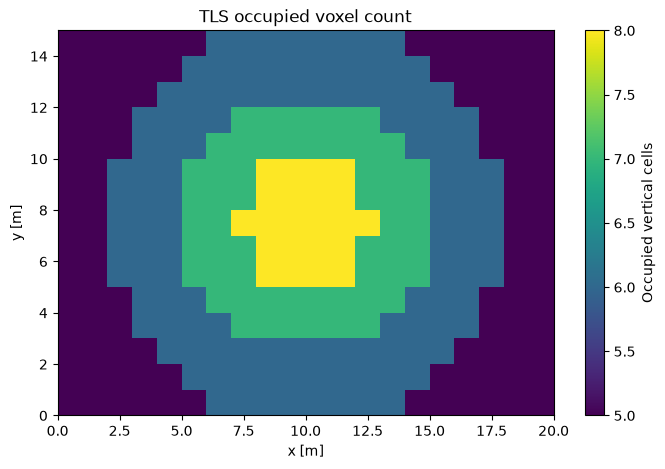

In [6]:
tls_height = tls_dataset.occupancy.sum("z")
fig, ax = plt.subplots(figsize=(8, 5))
image = ax.pcolormesh(grid.x, grid.y, tls_height, shading="nearest")
ax.set(xlabel="x [m]", ylabel="y [m]", title="TLS occupied voxel count")
fig.colorbar(image, ax=ax, label="Occupied vertical cells")
plt.show()

## Optionally add ALS

A two-dimensional canopy-height layer may use the matching `x` and `y` subset of the three-dimensional grid. No GEDI or tomogram placeholder is needed.

In [7]:
als_dataset = xr.Dataset(
    {"canopy_height": (("y", "x"), canopy_height.astype("float32"))},
    coords={"x": grid.x, "y": grid.y},
    attrs={"crs": grid.crs},
)
cube.add_layer(
    DataLayer(
        name="als_canopy_height",
        data=als_dataset,
        modality=Modality.ALS,
        geometry=GeometryType.RASTER,
    )
)
print("Present after adding ALS:", sorted(cube.modalities))
print("Missing after adding ALS:", sorted(cube.missing_modalities(expected)))

Present after adding ALS: ['als', 'tls']
Missing after adding ALS: ['gedi', 'tomogram']


## Build the visualization dataset

`to_xarray()` combines only available layers. Variable names are prefixed with their layer names to avoid collisions.

In [8]:
visualization_data = cube.to_xarray()
visualization_data

<xarray.Dataset> Size: 5kB
Dimensions:                           (x: 20, y: 15, z: 10)
Coordinates:
  * x                                 (x) float64 160B 0.5 1.5 2.5 ... 18.5 19.5
  * y                                 (y) float64 120B 0.5 1.5 2.5 ... 13.5 14.5
  * z                                 (z) float64 80B 0.5 1.5 2.5 ... 8.5 9.5
Data variables:
    tls_occupancy__occupancy          (z, y, x) bool 3kB True True ... False
    als_canopy_height__canopy_height  (y, x) float32 1kB 5.056 5.094 ... 5.056
Attributes:
    crs:         EPSG:32630
    modalities:  ['als', 'tls']

## Require modalities only when necessary

Most visualization paths should adapt to available layers. An operation that specifically compares TLS against BIOMASS tomography can explicitly require both and provide a clear error otherwise.

In [9]:
try:
    cube.require_modalities(Modality.TLS, Modality.TOMOGRAM)
except ValueError as error:
    print(error)

Missing required modalities: tomogram


## Validation prevents accidental misalignment

A layer with shifted coordinates or another CRS is rejected before it reaches visualization. Reprojection and resampling belong in processors/transforms and cube generation.

In [10]:
shifted_dataset = xr.Dataset(
    {"value": (("y", "x"), np.ones((grid.y.size, grid.x.size)))},
    coords={"x": grid.x + 100.0, "y": grid.y},
    attrs={"crs": grid.crs},
)
shifted_layer = DataLayer(
    name="shifted_example",
    data=shifted_dataset,
    modality=Modality.OTHER,
    geometry=GeometryType.RASTER,
)
try:
    cube.add_layer(shifted_layer)
except ValueError as error:
    print(error)

Layer coordinate 'x' does not match the cube grid
